In [1]:
# ═══════════════════════════════════════════════════════════════
# CELL 1 — Imports
# ═══════════════════════════════════════════════════════════════
from the_well.data.normalization import ZScoreNormalization
import sys, os, datetime, fsspec, torch, munch, toml, yaml
from the_well.data import WellDataModule
from torch.utils.data import DataLoader
import torch.nn.functional as F
import pytorch_lightning as pl
import shutil

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.configs import WaveletConfig, VelocityNetConfig, FlowMatchingConfig, OptimizerConfig
from waveletflux.utils.well_data import WellDataModuleLightning
from waveletflux.utils.augmentations import compose_augmentation
from waveletflux.utils.experiment import ExperimentManager
from waveletflux.modules.wavelet_fm import WaveletFlowModule
from waveletflux.models.wavelet_unet import WaveletFlowUNet

print("Imports OK | MPS:", torch.backends.mps.is_available())
print(f"MPS allocated : {torch.mps.current_allocated_memory() / 1e9:.2f} GB")
print(f"MPS reserved  : {torch.mps.driver_allocated_memory()  / 1e9:.2f} GB")

Imports OK | MPS: True
MPS allocated : 0.00 GB
MPS reserved  : 0.00 GB


In [2]:
well_base_path    = f"/Users/gabrieleaccarino/Workspace/multi-scale-wavelet-flow-matching/data/datasets"
well_dataset_name = 'planetswe'
stats_path        = f"{well_base_path}/{well_dataset_name}/stats.yaml"

In [3]:
augmentations = []

base_data_module = WellDataModule(
    well_base_path     = well_base_path,
    well_dataset_name  = well_dataset_name,
    n_steps_input      = 4,
    n_steps_output     = 1,
    max_rollout_steps  = 1,
    batch_size         = 1,
    use_normalization  = False,
    normalization_type = None,
    transform          = compose_augmentation(*augmentations),
    data_workers       = 10,
    world_size         = 1,
    rank               = 0,
)


In [4]:
with fsspec.open(stats_path, mode='r') as f:
    stats = yaml.safe_load(f)

normalizer = ZScoreNormalization(
    stats,
    core_field_names          = base_data_module.train_dataset.core_field_names,
    core_constant_field_names = base_data_module.train_dataset.core_constant_field_names,
)

data_shape  = base_data_module.train_dataset.metadata.spatial_resolution
meta_fields = base_data_module.train_dataset.metadata.field_names
field_names = [item for sublist in meta_fields.values() for item in sublist]

print(f"Fields: {field_names} | Shape: {data_shape}")

Fields: ['height', 'velocity_theta', 'velocity_phi'] | Shape: (256, 512)


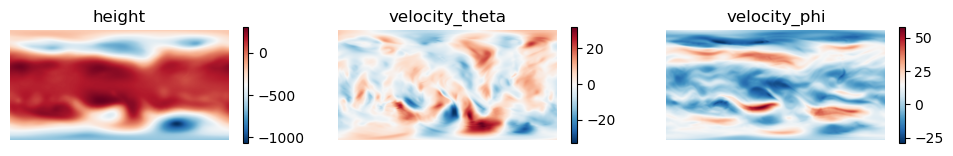

In [5]:
from matplotlib import pyplot as plt

item = base_data_module.train_dataset[0]
x = item['output_fields'] # (B, H, W, C)

plt.figure(figsize=(12, 6))

cmap = 'RdBu_r'

plt.subplot(1, 3, 1)
plt.title("height")
plt.imshow(x[0, ..., 0].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.25)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("velocity_theta")
plt.imshow(x[0, ..., 1].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.25)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("velocity_phi")
plt.imshow(x[0, ..., 2].numpy(), cmap=cmap)
plt.colorbar(shrink = 0.25)
plt.axis('off')

plt.show()

# Plot velocity theta on a different projection

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_37213/769204704.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


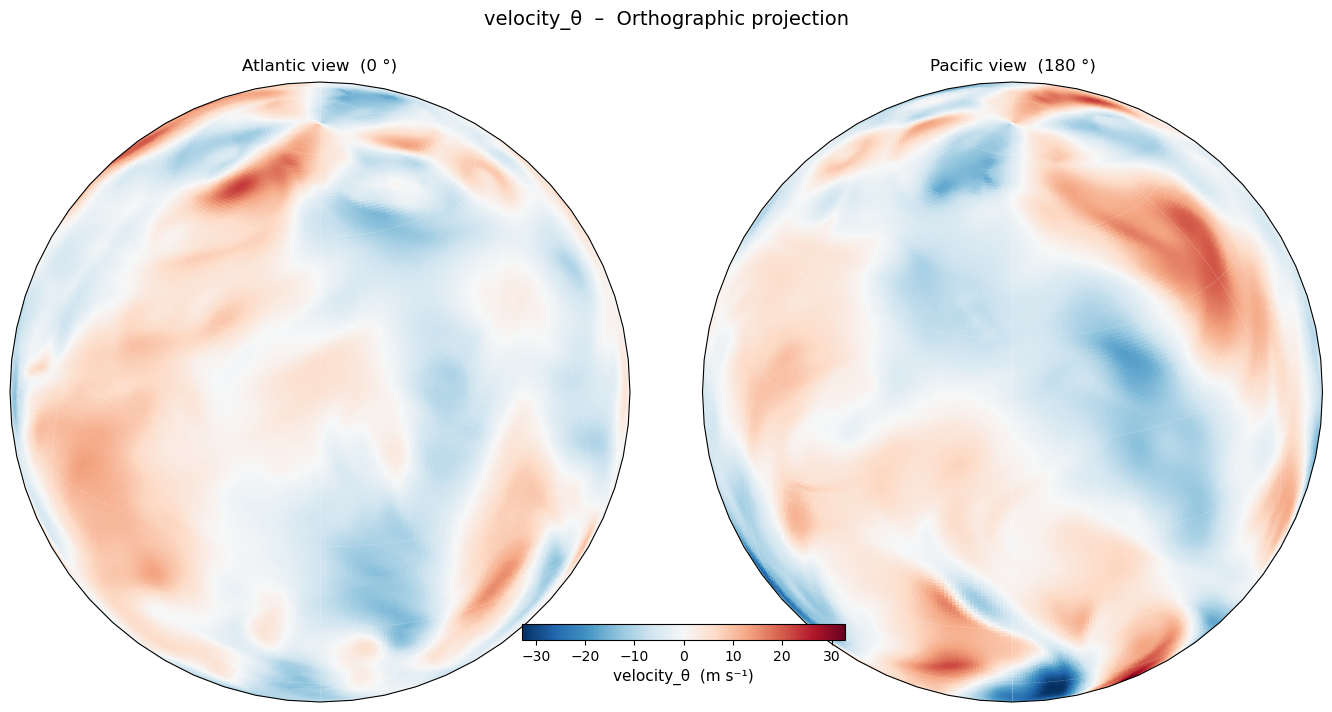

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib import cm

# --- grab the data ---
item = base_data_module.train_dataset[0]
x = item['output_fields']         # (B, H, W, C)
vel_theta = x[0, ..., 1].numpy()  # (H, W)

H, W = vel_theta.shape

# --- build lat/lon grids that match the array dimensions ---
# The Well planetary data lives on a regular lat/lon grid:
#   H rows  → latitudes  from +90° (north) to -90° (south)
#   W cols  → longitudes from   0° to 360°
lats = np.linspace(90,  -90, H)
lons = np.linspace(0,   360, W, endpoint=False)
lon2d, lat2d = np.meshgrid(lons, lats)

# --- colour scale (symmetric around 0 for a velocity field) ---
vmax = np.abs(vel_theta).max()
vmin = -vmax

# --- figure: two orthographic views (front + back) ---
fig = plt.figure(figsize=(14, 7))
fig.suptitle("velocity_θ  –  Orthographic projection", fontsize=14, y=1.01)

for col, (central_lon, title) in enumerate(
        [(0, "Atlantic view  (0 °)"), (180, "Pacific view  (180 °)")]):

    ax = fig.add_subplot(
        1, 2, col + 1,
        projection=ccrs.Orthographic(
            central_longitude=central_lon,
            central_latitude=30          # tilt slightly toward NH
        )
    )
    ax.set_global()

    # pcolormesh in PlateCarree coords → reprojected automatically
    mesh = ax.pcolormesh(
        lon2d, lat2d, vel_theta,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax,
        shading="auto",
    )

    # optional: coastlines give a nice planetary feel even for alien worlds
    # ax.coastlines(linewidth=0.4, color="k", alpha=0.4)

    ax.gridlines(
        linewidth=0.4, color="white",
        alpha=0.35, linestyle="--"
    )
    ax.set_title(title, pad=8)

# shared colorbar
cbar = fig.colorbar(
    mesh, ax=fig.axes,
    orientation="horizontal",
    fraction=0.03, pad=0.04,
    shrink=0.7
)
cbar.set_label("velocity_θ  (m s⁻¹)", fontsize=11)

plt.tight_layout()
plt.show()